# 02 — Preprocessing walkthrough

**Goal:** show, on the real data, what `preprocessing.py` does before the models see a row:
special codes and units, skip-logic fills, the column counts through the pipeline, and why the
leaky questions are kept out. Every number below is produced by the project functions themselves
(no re-implementation); fitting uses a fixed 60,000-row subsample of the training rows.

In [1]:
import sys
from collections import Counter

sys.path.append("..")  # import the project modules from the repo root

import numpy as np
import matplotlib.pyplot as plt

import gbm
import run
from preprocessing import (
    LEAKY_COLUMNS, STRUCTURAL_FILLS, clean_data, fit_preprocessor, leaky_features,
    load_data_cached, load_feature_names, load_feature_spec, load_special_codes,
    replace_special_codes, transform,
)

DATA_PATH = "../data/dataset"
x_train, x_test, y_train, _, _ = load_data_cached(DATA_PATH)  # cached in data/cache/raw.npz
names = load_feature_names(DATA_PATH)
spec, codes = load_feature_spec(), load_special_codes()
print("x_train", x_train.shape, "| x_test", x_test.shape)
print(f"positive rate (_MICHD = 1): {np.mean(y_train == 1):.3%}")

x_train (328135, 321) | x_test (109379, 321)
positive rate (_MICHD = 1): 8.830%


## 1. Special codes, per column
`eda/special_codes.json` lists, for each column, the codes that mean "don't know / refused" (→ NaN)
and "none" (→ 0). The rule is per column because 7 or 99 are real values elsewhere.

In [2]:
def show_mapping(col, max_rows=8):
    '''Print the raw code counts of one column next to their cleaned value.'''
    j = names.index(col)
    raw = x_train[:, [j]]
    clean = replace_special_codes(raw, [col], codes)[:, 0]
    rule = codes[col]
    print(f"{col}: nan_codes={rule['nan_codes']} zero_codes={rule['zero_codes']}")
    shown = sorted(set(rule["nan_codes"]) | set(rule["zero_codes"])) or []
    shown = [v for v in shown if np.any(raw == v)]
    vals, counts = np.unique(raw[:, 0], return_counts=True)
    shown += [v for v in vals[~np.isnan(vals)] if v not in shown][: max_rows - len(shown)]
    print(f"  {'raw':>6} {'count':>8}  ->  cleaned")
    for v in shown:
        m = raw[:, 0] == v
        new = clean[m][0]
        print(f"  {v:>6g} {m.sum():>8d}  ->  {'NaN' if np.isnan(new) else format(new, 'g')}")
    if np.isnan(raw).any():
        print(f"  {'NaN':>6} {np.isnan(raw).sum():>8d}  ->  NaN")
    print()

show_mapping("PHYSHLTH", max_rows=6)   # days of poor physical health: 88 = none, 77/99 = unknown
show_mapping("CHCKIDNY")               # yes/no question: 1 yes, 2 no, 7/9 unknown

PHYSHLTH: nan_codes=[77, 99] zero_codes=[88]
     raw    count  ->  cleaned
      77     5587  ->  NaN
      88   204264  ->  0
      99     1520  ->  NaN
       1    13676  ->  1
       2    18182  ->  2
       3    10553  ->  3
     NaN        1  ->  NaN

CHCKIDNY: nan_codes=[7, 9] zero_codes=[]
     raw    count  ->  cleaned
       7      908  ->  NaN
       9       69  ->  NaN
       1    11487  ->  1
       2   315671  ->  2



Weight is reported either in pounds (50–999) or as 9000 + kg. `WEIGHT2` is converted to kg;
it then matches the computed column `WTKG3`, which is the one we keep.

In [3]:
w_raw = x_train[:, names.index("WEIGHT2")]
w_kg = replace_special_codes(x_train[:, [names.index("WEIGHT2")]], ["WEIGHT2"], codes)[:, 0]
wtkg3 = replace_special_codes(x_train[:, [names.index("WTKG3")]], ["WTKG3"], codes)[:, 0]
for v in (150, 200, 9070):
    i = np.flatnonzero(w_raw == v)[0]
    print(f"WEIGHT2 raw {v:>5} -> {w_kg[i]:6.2f} kg   (WTKG3 = {wtkg3[i]:6.2f})")
print("7777/9999 (unknown) -> NaN:", int(np.isin(w_raw, [7777, 9999]).sum()), "rows")
both = ~np.isnan(w_kg) & ~np.isnan(wtkg3)
print(f"max |WEIGHT2 in kg - WTKG3| = {np.abs(w_kg[both] - wtkg3[both]).max():.3f} kg")

WEIGHT2 raw   150 ->  68.04 kg   (WTKG3 =  68.04)
WEIGHT2 raw   200 ->  90.72 kg   (WTKG3 =  90.72)
WEIGHT2 raw  9070 ->  70.00 kg   (WTKG3 =  70.00)
7777/9999 (unknown) -> NaN: 19055 rows
max |WEIGHT2 in kg - WTKG3| = 0.006 kg


## 2. Skip-logic fill
`BPMEDS` ("taking blood-pressure medication") is only asked when `BPHIGH4 = 1` (hypertension).
For people who answered no hypertension (2, 3, 4), its NaN means "no" and is filled with the raw
"no" code 2 (then recoded to 0).

In [4]:
print("rule:", [r for r in STRUCTURAL_FILLS if r[0] == "BPMEDS"][0])
xc_full, xc_names = clean_data(x_train, names)
bp_raw = x_train[:, names.index("BPMEDS")]
bp_clean = xc_full[:, xc_names.index("BPMEDS")]
gate = x_train[:, names.index("BPHIGH4")]
print(f"{'BPHIGH4':>16} {'rows':>8} {'NaN before':>11} {'NaN after':>10}")
for label, m in [("1 (hypertension)", gate == 1), ("2/3/4 (no)", np.isin(gate, [2, 3, 4])),
                 ("7/9/NaN", ~np.isin(gate, [1, 2, 3, 4]))]:
    print(f"{label:>16} {m.sum():>8d} {np.isnan(bp_raw[m]).sum():>11d} {np.isnan(bp_clean[m]).sum():>10d}")
print(f"total NaN share of BPMEDS: {np.isnan(bp_raw).mean():.1%} -> {np.isnan(bp_clean).mean():.1%}")

rule: ('BPMEDS', [('BPHIGH4', [2, 3, 4])], 2)


         BPHIGH4     rows  NaN before  NaN after
1 (hypertension)   131801           0        216
      2/3/4 (no)   195416      195416          0
         7/9/NaN      918         918        918
total NaN share of BPMEDS: 59.8% -> 0.3%


## 3. Columns through the pipeline
`clean_data` keeps the spec rows whose kind is not `drop` and appends one `_dk` ("don't know /
refused") flag per kept question with such codes. The MLP pipeline (`run.MLP_CONFIG`) is fitted on a
60,000-row subsample here; in `run.py` it is fitted on all training rows.

In [5]:
kinds = Counter(r["kind"] for r in spec)
print("feature_spec kinds:", dict(kinds))

rng = np.random.default_rng(0)
sub = np.sort(rng.choice(len(y_train), 60_000, replace=False))
xc, xc_names, _ = run.model_inputs(x_train[sub], names)  # clean_data + raw _STATE last
n_dk = sum(n.endswith("_dk") for n in xc_names)
x_gbm = gbm.tree_features(xc, xc_names)
state = fit_preprocessor(xc[:, :-1], xc_names[:-1], run.MLP_CONFIG, y=y_train[sub])
tx = transform(xc[:, :-1], state)
out = state["out_names"]
print(f"clean_data: {xc.shape[1] - 1} columns = {xc.shape[1] - 1 - n_dk} features + {n_dk} '_dk' flags")
print("GBM input :", x_gbm.shape, "(NaN kept:", bool(np.isnan(x_gbm).any()), ")")
print("MLP input :", tx.shape, "(NaN:", bool(np.isnan(tx).any()), ")")
print("  kept by fit_preprocessor:", dict(Counter(state["kinds"])))
print(f"  = 1 bias + {len(state['numeric_idx'])} numeric/binary + {sum('=' in n for n in out)} one-hot dummies"
      f" + {sum(n.endswith('_nan') for n in out)} missing indicators")

feature_spec kinds: {'drop': 246, 'ordinal': 6, 'continuous': 9, 'binary': 35, 'onehot': 11, 'continuous_log': 16}


clean_data: 138 columns = 77 features + 61 '_dk' flags
GBM input : (60000, 139) (NaN kept: True )
MLP input : (60000, 140) (NaN: False )
  kept by fit_preprocessor: {'ordinal': 6, 'continuous': 9, 'binary': 35, 'onehot': 11, 'continuous_log': 16}
  = 1 bias + 66 numeric/binary + 40 one-hot dummies + 33 missing indicators


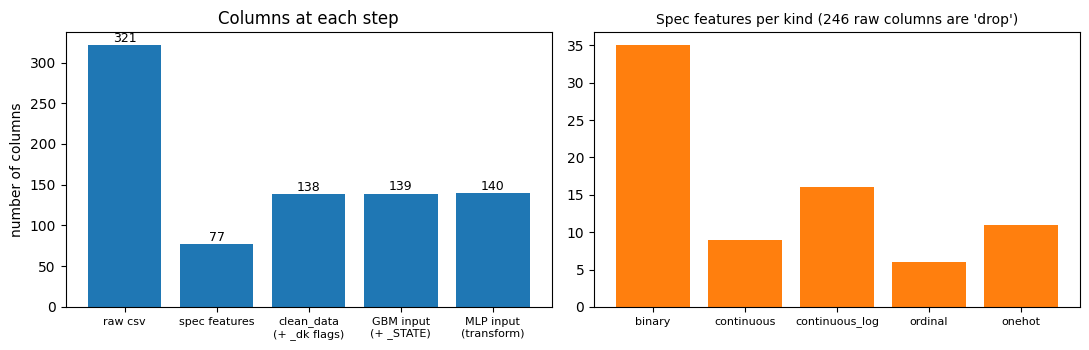

In [6]:
steps = {"raw csv": x_train.shape[1], "spec features": xc.shape[1] - 1 - n_dk,
         "clean_data\n(+ _dk flags)": xc.shape[1] - 1, "GBM input\n(+ _STATE)": x_gbm.shape[1],
         "MLP input\n(transform)": tx.shape[1]}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(list(steps), list(steps.values()), color="tab:blue")
for i, v in enumerate(steps.values()):
    axes[0].text(i, v + 4, str(v), ha="center", fontsize=9)
axes[0].set_ylabel("number of columns")
axes[0].set_title("Columns at each step")
axes[0].tick_params(axis="x", labelsize=8)
order = ["binary", "continuous", "continuous_log", "ordinal", "onehot"]
axes[1].bar(order, [kinds[k] for k in order], color="tab:orange")
axes[1].set_title(f"Spec features per kind ({kinds['drop']} raw columns are 'drop')", fontsize=10)
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

## 4. Leaky columns
These questions belong to the cardiovascular module asked after a heart attack or stroke. They are
consequences of the label, not risk factors, so they are `drop` in the spec. The table compares the
positive rate among people who answered with the overall rate.

In [7]:
meaning = {
    "HAREHAB1": "rehabilitation after a heart attack",
    "STREHAB1": "rehabilitation after a stroke",
    "CVDASPRN": "takes aspirin daily / every other day",
    "RDUCHART": "aspirin to reduce heart attack risk",
    "RDUCSTRK": "aspirin to reduce stroke risk",
    "RLIVPAIN": "aspirin to relieve pain",
    "ASPUNSAF": "aspirin unsafe for the respondent",
}
base = np.mean(y_train == 1)
print(f"{'column':<9} {'meaning':<39} {'answered':>8} {'pos. rate':>9} {'lift':>5}")
for c in LEAKY_COLUMNS:
    col = x_train[:, names.index(c)]
    ans = ~np.isnan(col)
    rate = np.mean(y_train[ans] == 1)
    print(f"{c:<9} {meaning[c]:<39} {ans.sum():>8d} {rate:>9.1%} {rate / base:>5.1f}")
print(f"{'overall':<9} {'':<39} {len(y_train):>8d} {base:>9.1%}")

column    meaning                                 answered pos. rate  lift
HAREHAB1  rehabilitation after a heart attack          773    100.0%  11.3
STREHAB1  rehabilitation after a stroke                517     35.8%   4.1
CVDASPRN  takes aspirin daily / every other day      14046      9.4%   1.1
RDUCHART  aspirin to reduce heart attack risk         4194     20.8%   2.4
RDUCSTRK  aspirin to reduce stroke risk               4193     20.8%   2.4
RLIVPAIN  aspirin to relieve pain                     4193     20.8%   2.4
ASPUNSAF  aspirin unsafe for the respondent           9851      4.5%   0.5
overall                                             328135      8.8%


`HAREHAB1` is answered only by positives (a perfect label proxy); `STREHAB1` is 4× enriched and the
aspirin-purpose questions 2.4×. `CVDASPRN` and `ASPUNSAF` are not enriched alone but belong to the same
post-event module. None of them reaches the official model; they exist only in the
`--with_leakage` variant through `leaky_features`.

In [8]:
print("in clean_data output   :", [c for c in LEAKY_COLUMNS if c in xc_names])
x_gbm_names = [n for n in xc_names if n not in LEAKY_COLUMNS]
print("in gbm.tree_features   :", [c for c in LEAKY_COLUMNS if c in x_gbm_names])
print("in MLP input (out_names):", [c for c in LEAKY_COLUMNS if any(n.startswith(c) for n in out)])
x_tree, tree_names, x_flags, flag_names = leaky_features(x_train[sub], names)
print("leaky_features: tree block", x_tree.shape, "| 0/1 flags", x_flags.shape)
print("GBM input with leakage :", gbm.tree_features(xc, xc_names, x_tree).shape, "vs", x_gbm.shape)

in clean_data output   : []
in gbm.tree_features   : []
in MLP input (out_names): []
leaky_features: tree block (60000, 14) | 0/1 flags (60000, 29)
GBM input with leakage : (60000, 153) vs (60000, 139)


## 5. What each model receives
- **GBM** (`gbm.tree_features`): the `clean_data` matrix with NaN kept (NaN is its own bin), the
  `_dk` flags, and the raw `_STATE`, later replaced by its smoothed prevalence fitted on training rows.
- **MLP** (`fit_preprocessor` + `transform` with `run.MLP_CONFIG`): selected columns, binary recode,
  median/mode imputation, one-hot dummies, missing indicators, log1p of counts, standardization and a
  bias; no NaN. All statistics come from the training rows (training folds in cross-validation).